<a href="https://colab.research.google.com/github/Thomas1603/2026_Intro_Python/blob/main/FEEDBACK_THOMAS_JORDAN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Exercise 20: Global surface air temperature and its zonal mean

The three files cached below hold one snapshot of surface air temperature from the
[NCEP/NCAR atmospheric reanalysis 1](https://psl.noaa.gov/data/gridded/data.ncep.reanalysis.html),
as plain numpy arrays: `lon` (192 longitudes), `lat` (94 latitudes, running north to south), and
`temp_kelvin`, the field itself with shape `(94, 192)` — **in kelvin**.

<img src="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/part-I/_static/1.4-target-global-temperature.png" alt="A filled contour map of global surface air temperature in magma colours with a white dashed contour at minus ten degrees, beside a line plot of the zonal mean against latitude" width="100%">

<em>The figure to replicate. Left: the field as filled contours, with a single white contour drawn
at −10 °C. Right: the zonal mean — the average along longitude — against latitude.</em>


Rebuild it, and say in a comment which hemisphere's winter this snapshot was taken in, and how
the zonal mean tells you.

In [1]:
# Pre-supplied: download the three arrays and cache them locally.
import pooch
base_url = "https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/data/part-I/"
path_lon = pooch.retrieve(
    url=base_url + "ncep_global_temp_lon.npy",
    known_hash="sha256:eaf54b88dd89279d3034da17fe8470dc2c841bf9fa89b2aa741dacff9c326cdb",
    fname="ncep_global_temp_lon.npy",
    path=pooch.os_cache("mlees"),
)
path_lat = pooch.retrieve(
    url=base_url + "ncep_global_temp_lat.npy",
    known_hash="sha256:af1f438080460e1fca4583b2ec19b44285a3d3776e4d21b8da9b6e162906c88a",
    fname="ncep_global_temp_lat.npy",
    path=pooch.os_cache("mlees"),
)
path_temp = pooch.retrieve(
    url=base_url + "ncep_global_temp_kelvin.npy",
    known_hash="sha256:e040ca257334708b43e86398e09a5669fcf051179ecf5dcd278f758d67beed20",
    fname="ncep_global_temp_kelvin.npy",
    path=pooch.os_cache("mlees"),
)

ValueError: x and y must have same first dimension, but have shapes (192,) and (94,)

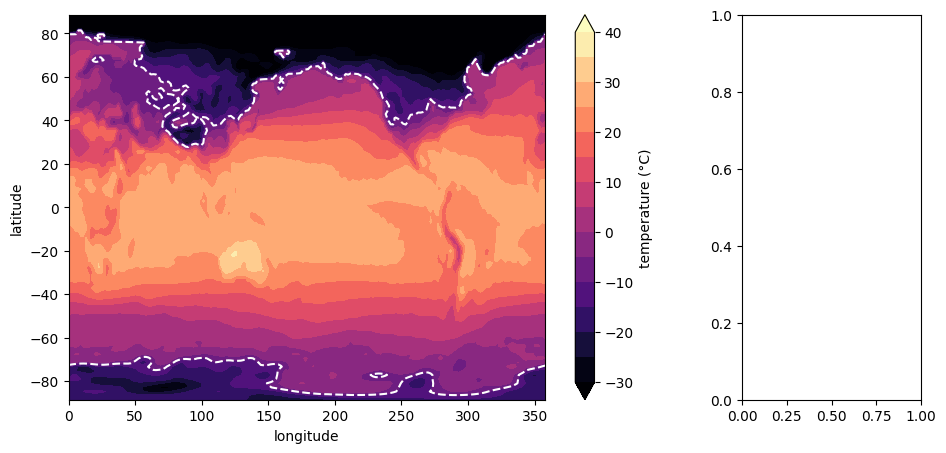

In [9]:
# Your solution here
import numpy as np
import matplotlib.pyplot as plt
import xarray as xr

lon = np.load(path_lon)
lat = np.load(path_lat)
temp_celsius = np.load(path_temp) - 273.15

fig, (ax1,ax2) = plt.subplots(1, 2, figsize=(11, 5), gridspec_kw={"width_ratios": [5, 1.5]})


contour = ax1.contourf(lon,lat,temp_celsius,levels=np.linspace(-30, 40, 15),cmap='magma',extend='both')

ax1.contour(lon,lat,temp_celsius,levels = [-10],colors='w')

ax1.set_xlabel("longitude")
ax1.set_ylabel("latitude")

cbar = fig.colorbar(contour, ax=ax1, label="temperature (°C)")

zonal_mean = np.nanmean(temp_celsius, axis = 0)

ax2.plot(zonal_mean, lat, c='black')
ax2.grid(True)

ax2.set_ylabel("latitude")
ax2.set_xlabel("temperature (°C)")


ax1.set_title("global surface air temperature")
ax2.set_title("zonal mean")
plt.tight_layout()

In my first attempt at this exercise, I got the error shown above. It's a problem with the dimensions of the x and y arguments on line 24. So I displayed their sizes to better understand the problem.

In [10]:
print(zonal_mean.shape)
print(lat.shape)

(192,)
(94,)


“zonal_mean” therefore has a size of 192. However, the number of values in ‘zonal_mean’ must be the same as in “latitude.”
So I modified the definition of my “zonal_mean” variable to ensure that the averages are calculated for the longitudes along the latitudes, and not the opposite. To do this, I simply changed “axis = 0” to “axis = 1.”

In [11]:
zonal_mean = np.nanmean(temp_celsius, axis = 1)
print(zonal_mean.shape)
print(lat.shape)

(94,)
(94,)


Our two variables are now the same size. So we can try again to plot the zonal mean.

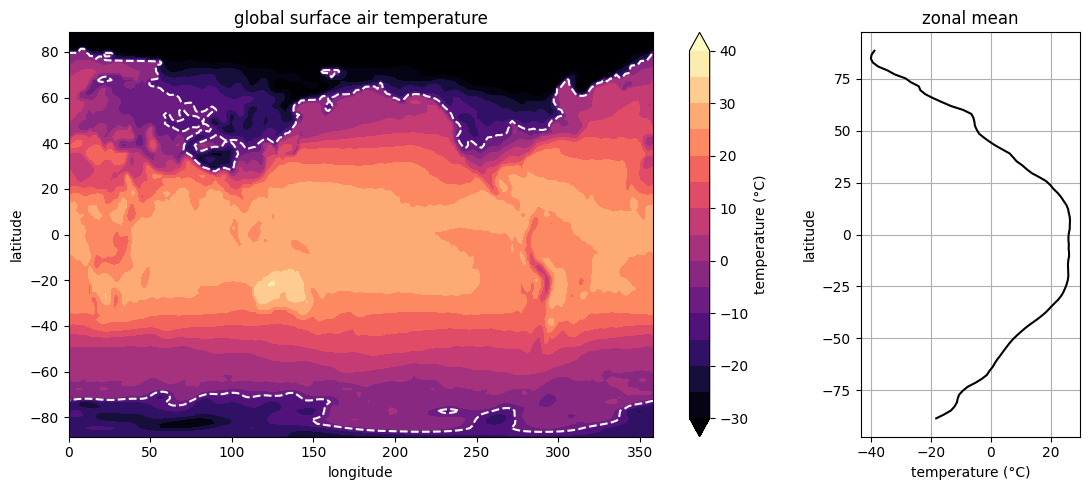

In [12]:
# Your solution here
import numpy as np
import matplotlib.pyplot as plt
import xarray as xr

lon = np.load(path_lon)
lat = np.load(path_lat)
temp_celsius = np.load(path_temp) - 273.15

fig, (ax1,ax2) = plt.subplots(1, 2, figsize=(11, 5), gridspec_kw={"width_ratios": [5, 1.5]})


contour = ax1.contourf(lon,lat,temp_celsius,levels=np.linspace(-30, 40, 15),cmap='magma',extend='both')

ax1.contour(lon,lat,temp_celsius,levels = [-10],colors='w')

ax1.set_xlabel("longitude")
ax1.set_ylabel("latitude")

cbar = fig.colorbar(contour, ax=ax1, label="temperature (°C)")

zonal_mean = np.nanmean(temp_celsius, axis = 1)

ax2.plot(zonal_mean, lat, c='black')
ax2.grid(True)

ax2.set_ylabel("latitude")
ax2.set_xlabel("temperature (°C)")


ax1.set_title("global surface air temperature")
ax2.set_title("zonal mean")
plt.tight_layout()